In [1]:
pip install tensorflow matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# ---------------------------------------------
# Practical 2: Feedforward Neural Network (ANN)
# ---------------------------------------------

# Step a: Import required packages
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

In [ ]:




data = np.load('mnist_dataset.npz')
print(data.files)

['X_train', 'y_train', 'X_test', 'y_test']


In [9]:
# Step b: Load training and testing data (MNIST - Local File)
# Make sure 'mnist_dataset.npz' is in the same folder as this notebook



with np.load('mnist_dataset.npz') as data:
    x_train, y_train = data['X_train'], data['y_train']
    x_test, y_test = data['X_test'], data['y_test']


In [10]:
# Normalize pixel values (0–255) → (0–1) for faster training
x_train = x_train / 255.0
x_test = x_test / 255.0


In [11]:
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)


Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


In [13]:
from tensorflow.keras import Input, layers, Sequential

model = Sequential([
    Input(shape=(28, 28)),                   # Define input shape here
    layers.Flatten(),                        # Flatten layer (no need to mention shape again)
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])


In [14]:
# Step d: Compile the model
# Using SGD (Stochastic Gradient Descent) as optimizer
model.compile(optimizer='sgd',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


In [15]:
# Step e: Train the model
history = model.fit(x_train, y_train, epochs=5, batch_size=32, validation_split=0.1)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8298 - loss: 0.6482 - val_accuracy: 0.9227 - val_loss: 0.2815
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9127 - loss: 0.3069 - val_accuracy: 0.9405 - val_loss: 0.2199
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9284 - loss: 0.2526 - val_accuracy: 0.9498 - val_loss: 0.1900
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9383 - loss: 0.2177 - val_accuracy: 0.9567 - val_loss: 0.1661
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9456 - loss: 0.1911 - val_accuracy: 0.9610 - val_loss: 0.1498


In [16]:
# Step f: Evaluate the model on test data
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print("\nTest Accuracy:", test_acc)


313/313 - 1s - 3ms/step - accuracy: 0.9484 - loss: 0.1811

Test Accuracy: 0.9484000205993652


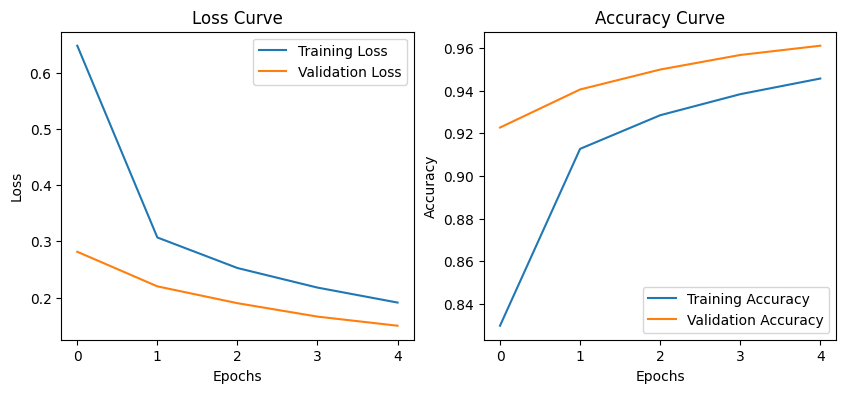

In [17]:
# Step g: Plot training loss and accuracy
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Accuracy Curve")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.show()